[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/13_retina_stimulus_features_per_scale.ipynb)

# Retina: stimulus features at each noise scale

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Task 2 of the note *Scale-resolved decomposition of G(x)* for the retina: estimate the stimulus features $M^{\rm env}_t(x) = \frac1t\,\mathbb{E}[\mathrm{Cov}(X \mid x_t)]$ at each noise scale from the unconditional model, and draw their leading eigenvectors above those of $M_t(x)$ for the mosaics of W3 and tOFFalpha cells (notebook 12), as notebook 8 does for V1 and V4.

* **Requirements**: as notebook 12 (`openretina` from the private repository `open-retina-multigeom`, the retina checkpoints, TinyImageNet, a GPU), and its stored results of $M_t(x)$ (run notebook 12 first).

* **Time**: about 25 min on a GPU, or seconds when the stored results are reloaded.

## 1. Setup

### 1.1. Install package

As in notebook 12: `multigeom` from the `g-per-scale` branch, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`).

time: <1 sec

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {"download_tinyimagenet": []},
        "multigeom.encoders.retina": {"load_retina": ["normalizer_cache"]},
        "multigeom.pipeline.per_scale": {"compute_env": []},
        "multigeom.plotting": {"plot_per_scale": []},
        "multigeom.utils": {
            "get_device": [],
            "load_intermediate": [],
            "save_intermediate": [],
        },
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 3.14 s, sys: 70.6 ms, total: 3.21 s
Wall time: 604 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the two cell types, the cell type whose diffusion model gives the model of the stimulus statistics, the samples per noise scale, and where the results and figures go.

<details><summary>Details</summary>

* `compute_env` estimates the stimulus features $M^{\rm env}_t(x)$ of each image at each noise scale from the null token of a diffusion model (`multigeom.compute_env_per_scale`); `plot_per_scale` draws them above $M_t(x)$ of each cell type.

</details>

time: 1 sec

In [2]:
%%time

import copy
import os
from pathlib import Path

import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.encoders.retina import load_retina
from multigeom.pipeline.per_scale import compute_env
from multigeom.plotting import plot_per_scale
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the two cell types and the area of their models (runs/<stage>/lorenzi/<area>/)
    "cell_types": {"W3": "retina-W3_176-exp7", "tOFFalpha": "retina-tOFFalpha_17-exp5"},
    # the cell type whose diffusion model gives the model of the stimulus statistics
    # (its null token, the unconditional model)
    "prior_cell_type": "W3",
    "frames": "data/tiny-imagenet-200/train",
    "normalizer": "data/02_intermediate/retina/normalizer.pt",
    # Monte-Carlo samples per noise scale: probes for the stimulus features (150, as
    # the pairs of responses of M_t(x) in notebook 12)
    "n_samples": 150,
    # probes per batch: a batch makes 2 x batch_size x n_noisy passes of the denoiser
    # at once (10: 160 passes, which fit in the GPU's memory at 120 x 120)
    "batch_size": 10,
    # the noisy images per probe and the finite-difference step in units of √t (N_x
    # and η of the note), and the shift of the seeds of the stimulus features, so that
    # their random draws are independent of those of M_t(x)
    "n_noisy": 8,
    "eta": 0.02,
    "env_seed_offset": 100_000,
    # leading eigenvectors kept and drawn at each noise scale
    "n_eigvecs": 4,
    # the stored results of notebook 12 (M_t(x) and the images), and where those of
    # this notebook go (True: recompute and overwrite them)
    "results_12": "data/02_intermediate/12_retina_eigenvectors_of_G_per_scale",
    "intermediate_dir": "data/02_intermediate/13_retina_stimulus_features_per_scale",
    "recompute": False,
    # where the figures are saved (one per image), their resolution in the file and
    # on screen, and the images whose figures stay in the notebook (each is about 1 MB)
    "figure_dir": "assets/figures/retina/v1/task2",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["img2"],
}

# the estimator config (packaged with multigeom)
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 660 ms, sys: 109 ms, total: 769 ms
Wall time: 774 ms


## 2. Download the retina models

As in notebook 12: the retina checkpoints on Hugging Face, with those of V1 and V4; only the retina ones are downloaded.

time: <1 sec

In [3]:
%%time

# download the retina checkpoints into runs/ (files that are already there are kept)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", allow_patterns="*/lorenzi/*"
)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

CPU times: user 31.1 ms, sys: 6.05 ms, total: 37.1 ms
Wall time: 143 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet, for the images the image units were fitted to (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

# the stored results of this notebook (and those it reuses), from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
from huggingface_hub import snapshot_download as download_results

if not PARAMS.get("recompute", False):  # recomputed anyway otherwise
    try:
        download_results(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=[
                f"{folder}/*"
                for folder in [
                    "12_retina_eigenvectors_of_G_per_scale",
                    "13_retina_stimulus_features_per_scale",
                    "retina",
                ]
            ],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

CPU times: user 535 μs, sys: 28 μs, total: 563 μs
Wall time: 442 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute the stimulus features $M^{\rm env}_t(x)$ at each noise scale

How uncertain the image remains once it is seen through noise of variance $t$, in each direction of image space, from the statistics of the images alone (no cells). We estimate it at the 24 noise scales of notebook 12, for each of its 6 test images, with the unconditional model of the W3 diffusion model, and keep its leading 4 eigenvectors and eigenvalues.

<details><summary>Details</summary>

* **Definition and algorithm.** Those of notebook 8: $M^{\rm env}_t(x) = \frac1t\, \mathbb{E}_{x_t \mid x}[\mathrm{Cov}(X \mid x_t)]$, estimated by central finite differences of the null-token denoiser along 150 random probes per noise scale, each averaged over 8 noisy images; the singular values of the rows are the eigenvalues.
* **The model of the stimulus statistics.** The null token of the W3 diffusion model: it was trained with 10% of the responses replaced by the null token, so it learned the posterior mean $\hat x(x_t) = \mathbb{E}[x \mid x_t]$ of TinyImageNet at 120 x 120. The stimulus features do not depend on the cells; the tOFFalpha model's null token should give the same, which we did not check.
* **Accuracy.** As in notebook 8, the fine scales are unreliable: there $M^{\rm env}_t$ is close to the identity in most directions, and 150 probes in 14,400 dimensions inflate its eigenvalues (the identity would come out near $\sqrt{14400/150} \approx 10$).
* **Stored results.** Saved in `data/02_intermediate/13_retina_stimulus_features_per_scale/` and reloaded by the next runs, unless `"recompute"` is True. $M_t(x)$ of the cell types comes from notebook 12's stored results.

</details>

time: 25 min (computed), or seconds (reloaded)

In [5]:
%%time

# 1. estimator settings: n_samples probes per noise scale in batches of batch_size,
# n_eigvecs eigenpairs kept
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.monte_carlo.batch_size = PARAMS["batch_size"]
cfg.top_k = PARAMS["n_eigvecs"]

# 2. M_t(x) of the cell types and the test images with their seeds, from notebook 12
results, examples = load_intermediate(Path(PARAMS["results_12"]) / "results.pt")

# 3. the stimulus features of every image, reloaded if stored, else computed from the
# null token of the prior cell type's diffusion model and stored; env[name] holds
# tau = log t, the eigenvalues and the eigenvectors
env_file = Path(PARAMS["intermediate_dir"]) / "stimulus_features.pt"
if env_file.exists() and not PARAMS["recompute"]:
    env = load_intermediate(env_file)
else:
    area = PARAMS["cell_types"][PARAMS["prior_cell_type"]]
    models = load_retina(
        area,
        Path("runs"),
        Path(PARAMS["frames"]),
        device,
        normalizer_cache=PARAMS["normalizer"],
    )
    env = compute_env(examples, models.unet, models.alphas_cumprod, cfg, device, PARAMS)
    save_intermediate(env, env_file)
print("stimulus features done:", len(env), "images")

/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.


stimulus features done: 6 images
CPU times: user 18min 43s, sys: 2.6 s, total: 18min 46s
Wall time: 18min 42s


## 5. Plot the stimulus features next to $M_t(x)$ at each noise scale

One figure per image, saved to `assets/figures/retina/v1/task2/stimulus_features_per_scale_<image>.png`; to keep the notebook small, it shows only those of the images in `PARAMS["show"]` (the bus). Each figure has the image (A), the leading 4 eigenvectors of the stimulus features $M^{\rm env}_t(x)$ (B), and those of $M_t(x)$ for W3 (C) and tOFFalpha (D), from the finest noise scale (left) to the coarsest (right); then the eigenvalues of the stimulus features (E), and those of the two cell types, each over its largest leading eigenvalue (F).

<details><summary>Details</summary>

* Each eigenvector is drawn as in notebooks 8 and 12. No receptive-field outlines: the mosaics tile the whole image (notebook 12).
* In E and F, the leading eigenvalue of each matrix is thick and the next three are thin, on linear axes; the stimulus features in their own panel, as they are (inflated at fine scales), and the cell types normalized, to compare where along $\tau$ they sit.

</details>

time: 15 secs

6 figures saved in assets/figures/retina/v1/task2
CPU times: user 15.4 s, sys: 327 ms, total: 15.7 s
Wall time: 14.3 s


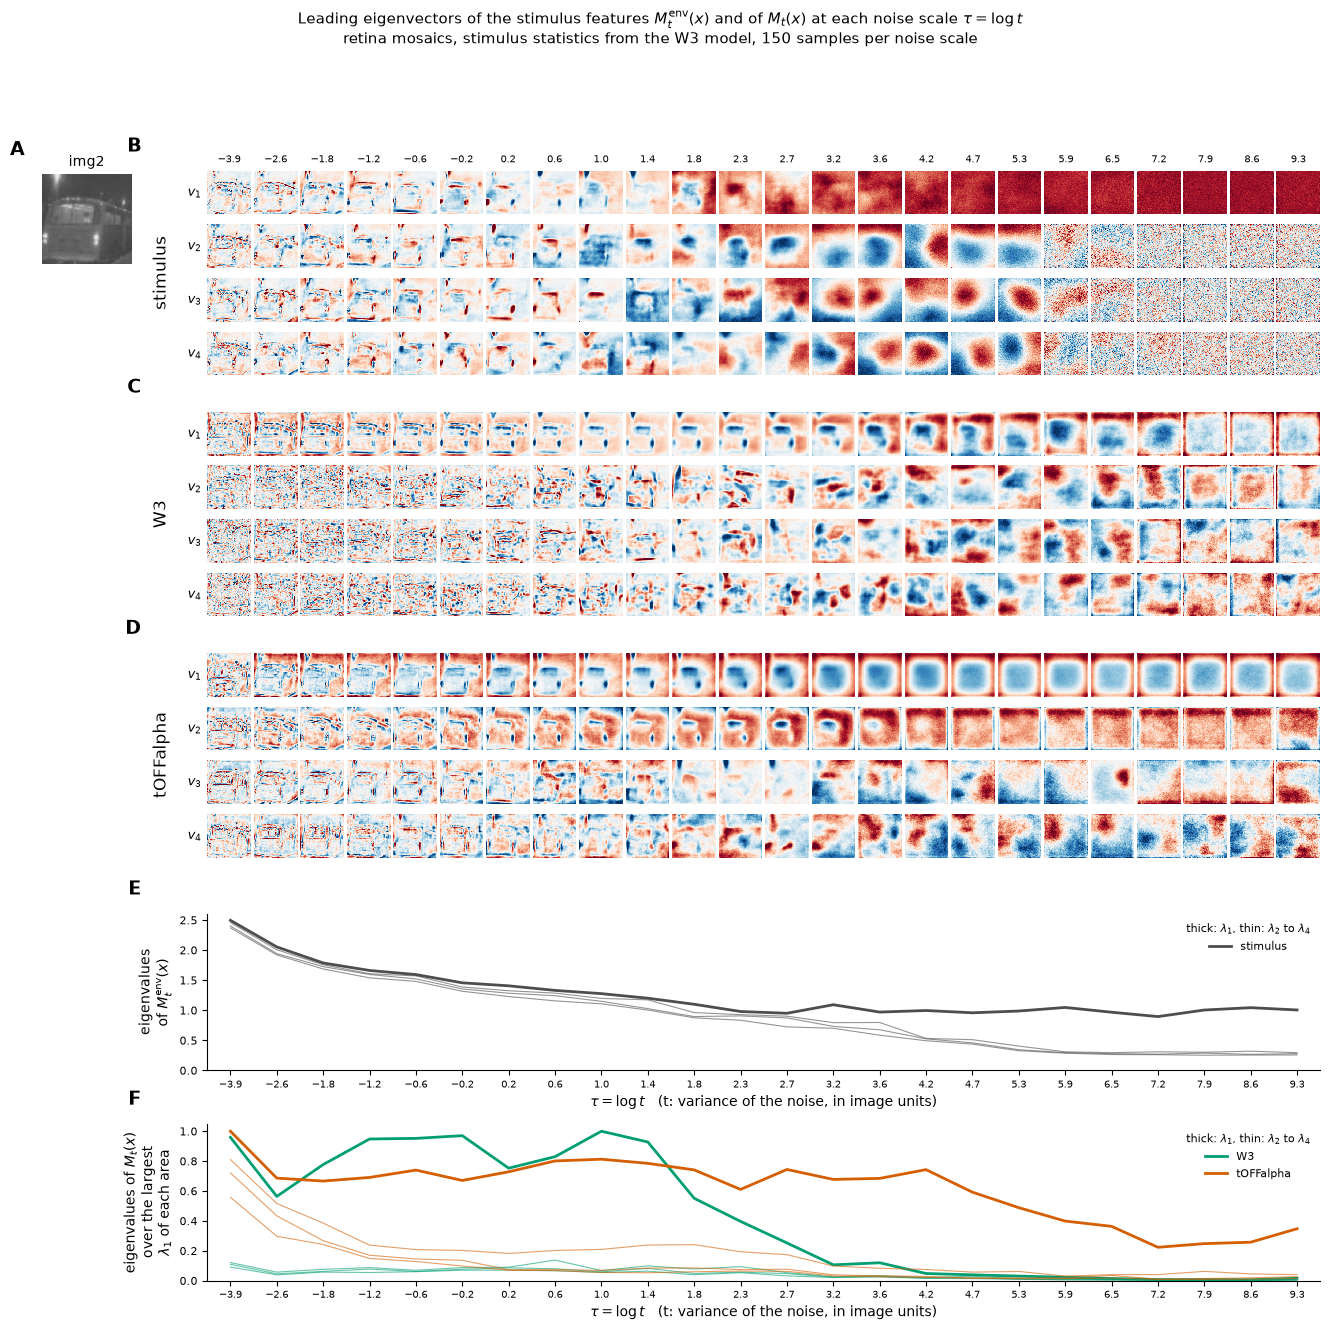

In [6]:
%%time

# 1. the folder of the figures, and the title of every figure
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
suptitle = (
    r"Leading eigenvectors of the stimulus features $M_t^{\rm env}(x)$ and of $M_t(x)$"
    r" at each noise scale $\tau = \log t$"
    f"\nretina mosaics, stimulus statistics from the {PARAMS['prior_cell_type']} model,"
    f" {PARAMS['n_samples']} samples per noise scale"
)

# 2. one figure per image, the stimulus features above the cell types: draw it, keep
# the data it shows, and save it; only the figures of the images in PARAMS["show"] stay
# in the notebook
plotted = {}
for name, (image, _) in examples.items():
    records = {"stimulus": env[name]}
    records.update({cell_type: results[cell_type][name] for cell_type in results})
    fig, plotted[name] = plot_per_scale(
        image.cpu(), records, PARAMS, name, suptitle, {}
    )
    fig.savefig(
        figure_dir / f"stimulus_features_per_scale_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)

# 3. where the figures are
print(len(plotted), "figures saved in", figure_dir)

## 6. Conclusion

To be written once the figures are checked.